In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as sp
import anndata as ad
import gseapy as gp
from copy import deepcopy
import scanpy.external as sce

# sc.logging.print_version()
sc.settings.verbosity = 3
sc.set_figure_params(figsize=(5,5))

import sys
from pathlib import Path

_start = Path.cwd().resolve()
_repo_root = next((p for p in [_start, *_start.parents] if (p / "chronopack").exists()), _start)
if str(_repo_root) not in sys.path:
    sys.path.insert(0, str(_repo_root))

from chronopack.preprocessing import (
    TIME_GROUP_CATEGORIES,
    add_time_metadata,
    annotate_qc_flags,
    filter_cells_by_qc,
    filter_technical_genes,
    load_time_tagged_anndata,
    map_time_to_group,
)
from chronopack.trajectories import (
    CalculateTerminalFatesAcrossCells,
    PlotHardClusterMassProportionsOverTime,
    cosine_topk_leiden_from_terminal_dist,
    extract_wot_couplings,
    fate_umap_2x2_scanpy,
    mass_retention_plots_and_umap,
    run_wot_transport_workflow,
    sparse_adjacency_from_tmats,
    terminal_fates_from_terminal_clusters,
    topk_csr_rows,
)


# Load preprocessing checkpoint


In [2]:
adata_full = sc.read_h5ad('../output/adata_full.chk0.h5ad')
bck = sc.read_h5ad('../output/adata_hvg.chk0.h5ad')


In [3]:
adata_c = bck.copy()

sc.pp.combat(adata_c, key='sample') # Batch correction on (log1p + residual) expression
sc.pp.regress_out(adata_c, keys=['total_counts', 'pct_counts_mt', 'S_score', 'G2M_score']) # Remove QC + cell-cycle effects first


Standardizing Data across genes.



Found 3 batches



Found 0 numerical variables:


Fitting L/S model and finding priors



Finding parametric adjustments



Adjusting data



regressing out ['total_counts', 'pct_counts_mt', 'S_score', 'G2M_score']


    finished (0:00:00)


In [4]:
adata_c.layers['corrected'] = adata_c.X.copy()

In [5]:
# Downstream
sc.pp.scale(adata_c, max_value=10)
sc.tl.pca(adata_c, n_comps=50)
sc.pp.neighbors(adata_c, n_neighbors=15, n_pcs=30)
sc.tl.umap(adata_c)

computing PCA


    with n_comps=50


    finished (0:00:09)


computing neighbors


    using 'X_pca' with n_pcs = 30


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:08)


computing UMAP


    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:11)


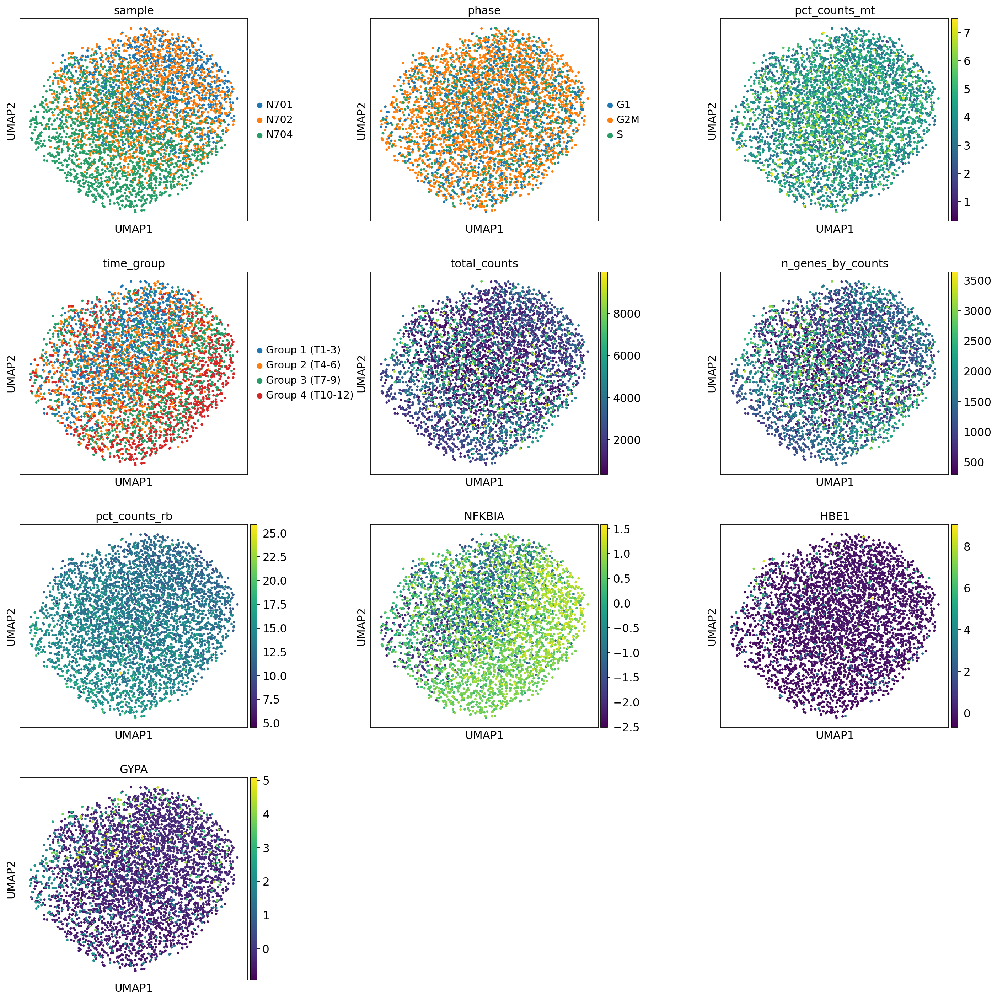

In [6]:
sc.pl.umap(adata_c, color=['sample', 'phase', 'pct_counts_mt', 'time_group', 'total_counts', 'n_genes_by_counts', 'pct_counts_rb', 'NFKBIA', 'HBE1', 'GYPA'], wspace=0.4, size=40, ncols=3)

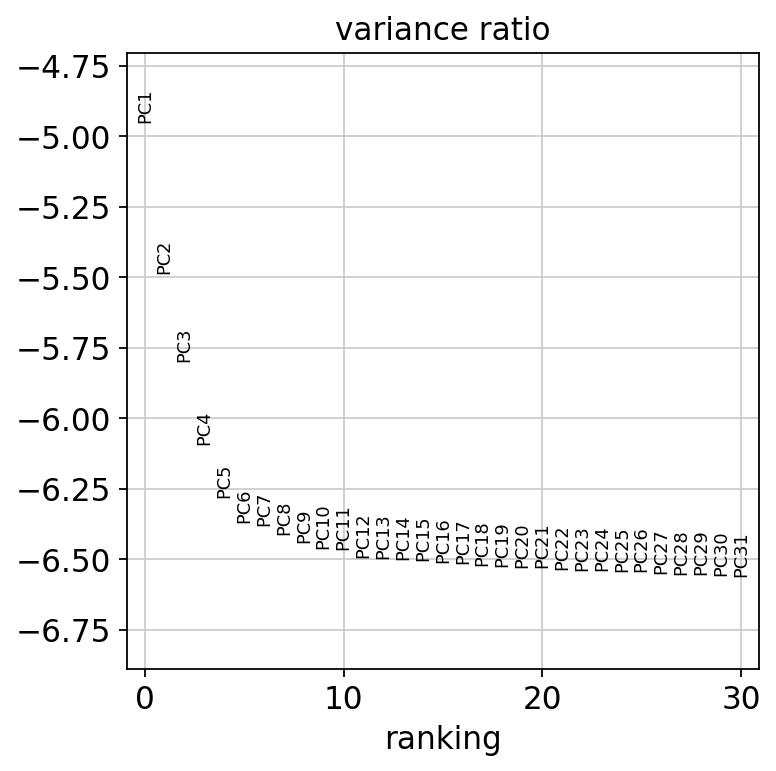

In [7]:
adata = adata_c.copy()
sc.pl.pca_variance_ratio(adata, n_pcs=30, log=True)

regressing out ['total_counts', 'pct_counts_mt', 'S_score', 'G2M_score']


    finished (0:00:00)


computing PCA


    with n_comps=50


    finished (0:00:10)


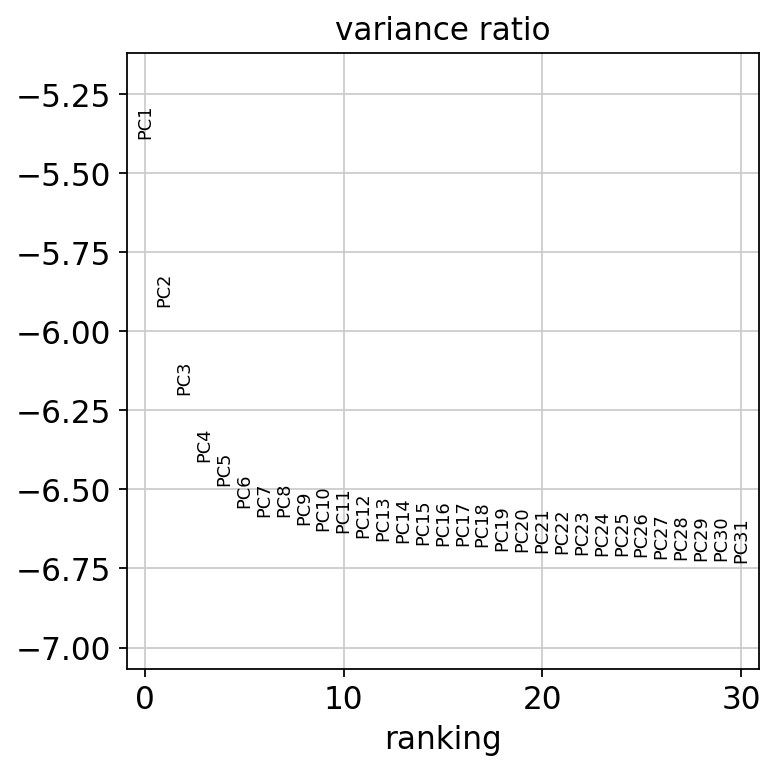

computing neighbors


    using 'X_pca' with n_pcs = 12


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)


computing UMAP


    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:09)


running Leiden clustering


/new-stg/home/alex/.tmp/ipykernel_973917/2546391553.py:8: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata, resolution=0.1, key_added='leiden_unintegrated')


    finished: found 1 clusters and added
    'leiden_unintegrated', the cluster labels (adata.obs, categorical) (0:00:00)


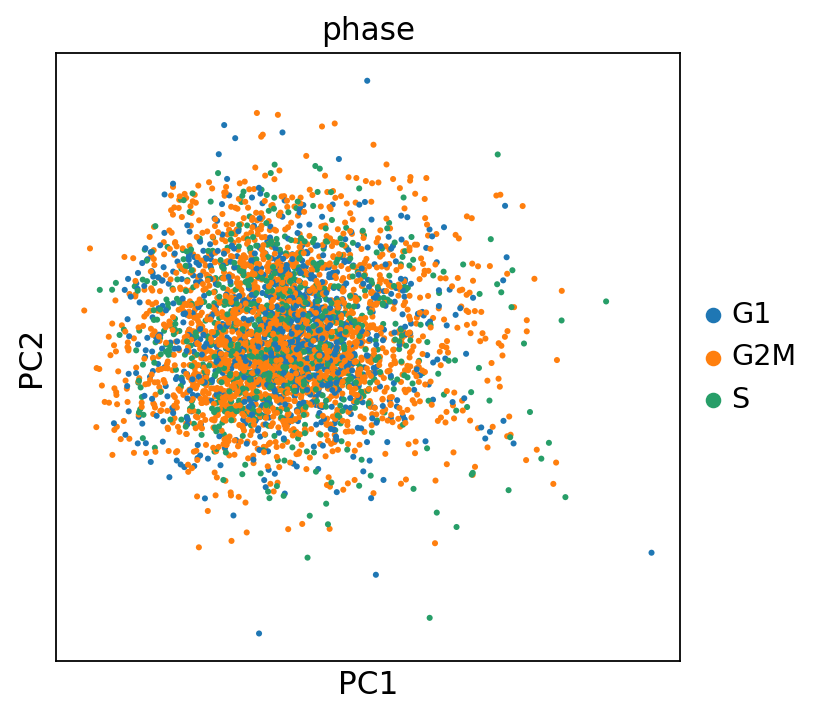

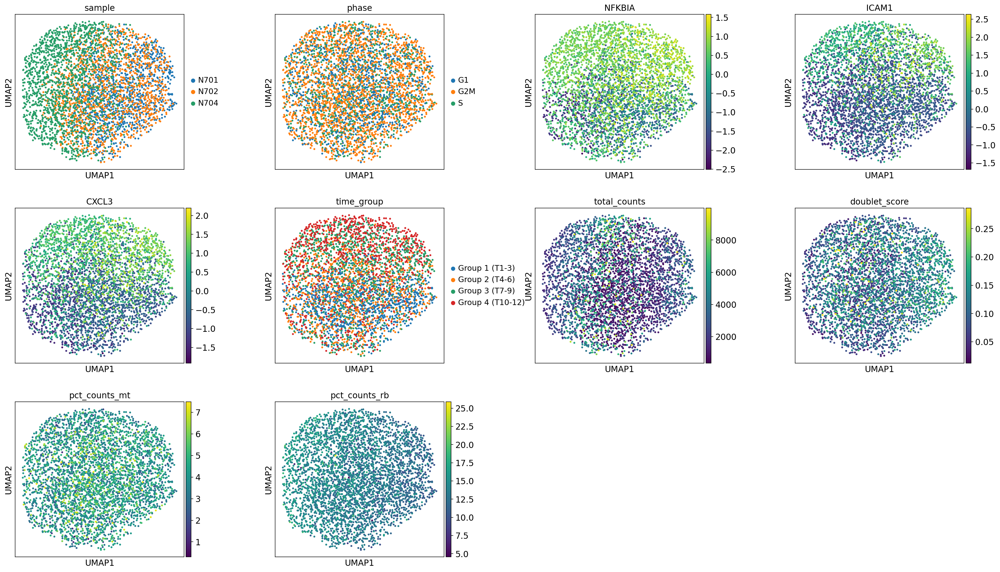

In [8]:
sc.pp.regress_out(adata, ['total_counts', 'pct_counts_mt', 'S_score', 'G2M_score'])
sc.pp.scale(adata)
sc.tl.pca(adata, n_comps=50, svd_solver='arpack')
sc.pl.pca_variance_ratio(adata, n_pcs=30, log=True)
sc.pp.neighbors(adata, n_pcs=12)

sc.tl.umap(adata)
sc.tl.leiden(adata, resolution=0.1, key_added='leiden_unintegrated')

sc.pl.pca_scatter(adata, color='phase')
sc.pl.umap(adata, color=['sample', 'phase', 'NFKBIA', 'ICAM1', 'CXCL3', 'time_group', 'total_counts', 'doublet_score', 'pct_counts_mt', 'pct_counts_rb'], wspace=0.4, size=40, ncols=4)

# Waddington‑OT (Transport maps)

In [9]:
adata.X = adata.layers['corrected']

wot_out = run_wot_transport_workflow(
    adata,
    tmap_dir='tmaps_sc/',
    ot_model_kwargs=dict(epsilon=0.05, lambda1=1, lambda2=50, growth_iters=3, day_field='time'),
    compute_transport_maps=True,
    transition_topk=30,
    symmetrize='average',
    use_unpruned_as_pruned=True,
    graph_key='ot_graph',
    umap_key='X_ot_umap',
    umap_random_state=10,
)

tmaps = wot_out['tmaps']
transitions_long = wot_out['transitions_long']
tmats = wot_out['tmats']
T_full = wot_out['T_full']
T_pruned = wot_out['T_pruned']
adata.obsp['t_pruned'] = T_pruned
T_sym = wot_out['T_sym']
key = 'X_ot_umap'
adata.obsm['X_umap'][:, 0] *= -1
adata.obsm[key] = adata.obsm['X_umap'].copy()


Built 11 transport matrices.


computing UMAP


    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:02)


In [10]:
# --- Visualize successor representation S for a single cell on an embedding ---
def plot_sr_for_cell(
    adata,
    S,
    cell=None,                  # int row index OR obs name (string). If None: random
    basis="umap",               # embedding name; expects adata.obsm['X_'+basis]
    colname="_sr_score",        # temp column in adata.obs
    normalize="l1",             # 'l1' | 'none' | 'z' (z-score)
    clip_quantile=0.995,        # clip color scale at this quantile (None = no clip)
    cmap="magma",
    size=8,
    keep_column=False,          # keep the column in adata.obs after plotting?
    ax=None,
    title=None,
    seed=0,
):
    import numpy as np, scipy.sparse as sp, scanpy as sc, matplotlib.pyplot as plt

    # --- pick the cell ---
    n = adata.n_obs
    if sp.issparse(S):
        S = S.tocsr()
    assert S.shape == (n, n), "S must be n_obs x n_obs"

    if cell is None:
        rng = np.random.default_rng(seed)
        i = int(rng.integers(0, n))
    elif isinstance(cell, str):
        i = int(adata.obs_names.get_loc(cell))
    else:
        i = int(cell)

    # --- row vector (successor weights) ---
    s = S.getrow(i).toarray().ravel() if sp.isspmatrix(S) else np.asarray(S[i]).ravel()

    # normalize (S from a power series often isn’t row-stochastic)
    if normalize == "l1":
        den = s.sum()
        if den > 0:
            s = s / den
    elif normalize == "z":
        mu, sd = np.nanmean(s), np.nanstd(s)
        if sd > 0:
            s = (s - mu) / sd
    # else: 'none'

    # choose vmax via quantile (ignore zeros so the scale adapts to the support of s)
    if clip_quantile is not None and np.isfinite(clip_quantile):
        pos = s[s > 0]
        vmax = np.quantile(pos, clip_quantile) if pos.size else s.max()
    else:
        vmax = None

    # add to obs and plot
    adata.obs[colname] = s
    if ax is None:
        _, ax = plt.subplots(1, 1, figsize=(6.2, 5.6))

    src = adata.obs_names[i]
    sc.pl.embedding(
        adata,
        basis=basis,
        color=[colname],
        color_map=cmap,
        vmin=0,
        vmax=vmax,
        na_color="lightgrey",
        size=size,
        frameon=False,
        ax=ax,
        title=title or f"{basis.upper()} — successor mass from '{src}'",
        show=False,
    )

    # highlight the source cell
    xy = adata.obsm[f"X_{basis}"][i]
    ax.scatter([xy[0]], [xy[1]], s=80, c="none", edgecolors="cyan", linewidths=2.0, zorder=5)

    if not keep_column:
        del adata.obs[colname]
    plt.show()
    return src, i

In [11]:
# Row-stochastic P from your T_pruned
P = T_pruned.tocsr().astype(float)
rs = np.asarray(P.sum(axis=1)).ravel(); rs[rs==0] = 1.0
P = sp.diags(1/rs) @ P

# Successor representation S = sum_{k=1..K} gamma^k P^k  (K≈8–12, gamma≈0.85–0.95)
K, gamma = 12, 0.9
S, Pk, w = sp.csr_matrix(P.shape), P.copy(), gamma
for _ in range(1, K+1):
    S += w * Pk
    Pk = Pk @ P
    w *= gamma

# W = 0.5 * (S+S.T)
W = S.maximum(S.T)
W = topk_csr_rows(W, 1000)

W.setdiag(1e-12)            # tiny self loop to avoid zero-degree rows
W.eliminate_zeros()

In [12]:
import numpy as np
import pandas as pd
import scipy.sparse as sp

# ============================================================
# Terminal-cell successor representation (a.k.a. absorption distribution)
#   Goal: for each cell i, compute a probability distribution over CELLS
#         in the LAST timepoint (terminal set), using your forward kernel.
#
#   Output:
#     D_full: (n_cells x n_terminal_cells) sparse CSR
#       D_full[i, j] = P( terminal_cell = idx_last[j] | start at cell i )
#     adata.obsm["terminal_cell_dist"] = D_full
#     adata.uns["terminal_cell_dist_idx_last"] = idx_last (global cell indices)
#
#   Notes:
#     - Assumes T_pruned only moves forward in time (DAG-like). Works even if it can skip bins
#       because we use "all future bins" each step.
#     - Uses TOP-K pruning per row to keep the distribution sparse & tractable.
# ============================================================

assert "T_pruned" in globals(), "Need T_pruned in scope."
assert sp.issparse(T_pruned), "T_pruned must be a scipy sparse matrix."
assert T_pruned.shape == (adata.n_obs, adata.n_obs), "T_pruned must be n_cells x n_cells."

time_key = "time"
T = T_pruned.tocsr().astype(np.float64)

# -------------------------
# Build time bins
# -------------------------
t = adata.obs[time_key]
if hasattr(t, "cat"):
    time_levels = list(t.cat.categories)
else:
    time_levels = sorted(pd.unique(t))
tt = t.to_numpy().astype(object)

idx_by_time_all = [np.where(tt == lvl)[0] for lvl in time_levels]
idx_by_time = [ii for ii in idx_by_time_all if ii.size > 0]
time_levels_nonempty = [lvl for lvl, ii in zip(time_levels, idx_by_time_all) if ii.size > 0]
assert len(idx_by_time) >= 2, "Need at least 2 timepoints."

idx_last = idx_by_time[-1]
n_last = idx_last.size
n = adata.n_obs
print(f"Terminal timepoint: {time_levels_nonempty[-1]} | n_terminal={n_last}")

# -------------------------
# Helper: keep top-k entries per row in CSR
# -------------------------
def topk_csr_rows(M_csr, k=200, renorm=True, eps=1e-15):
    """
    Keep only top-k values per row of CSR matrix.
    Optionally renormalize each row to sum to 1.
    """
    M = M_csr.tocsr()
    n_rows = M.shape[0]
    indptr = [0]
    indices = []
    data = []

    for i in range(n_rows):
        start, end = M.indptr[i], M.indptr[i+1]
        cols = M.indices[start:end]
        vals = M.data[start:end]
        nnz = vals.size

        if nnz == 0:
            indptr.append(indptr[-1])
            continue

        if nnz > k:
            keep = np.argpartition(vals, -k)[-k:]
            # sort kept entries by descending value for determinism
            order = keep[np.argsort(-vals[keep])]
            cols = cols[order]
            vals = vals[order]
        else:
            order = np.argsort(-vals)
            cols = cols[order]
            vals = vals[order]

        if renorm:
            s = vals.sum()
            if s > 0:
                vals = vals / (s + eps)

        indices.extend(cols.tolist())
        data.extend(vals.tolist())
        indptr.append(len(indices))

    out = sp.csr_matrix((np.asarray(data, dtype=np.float64),
                         np.asarray(indices, dtype=np.int32),
                         np.asarray(indptr, dtype=np.int64)),
                        shape=M.shape)
    out.eliminate_zeros()
    return out

# -------------------------
# DP over time bins: compute D_t = dist over terminal cells for cells in time bin t
# -------------------------
# D_by_time[t] has shape (n_cells_in_bin_t, n_last)
D_by_time = [None] * len(idx_by_time)

# Terminal: each terminal cell maps to itself => identity in terminal-index space
D_by_time[-1] = sp.identity(n_last, format="csr", dtype=np.float64)

# Backward DP: for each earlier bin, map to all future bins
#   D_t = rownorm( T[t_cells, future_cells] ) @ D_future
topk = 200  # increase if you want a less sparse distribution per cell (e.g., 500-2000)
eps = 1e-15

for ti in range(len(idx_by_time) - 2, -1, -1):
    ii = idx_by_time[ti]
    future_idx = np.concatenate(idx_by_time[ti+1:])
    # stack future distributions in the same order as future_idx
    D_future = sp.vstack([D_by_time[j] for j in range(ti+1, len(idx_by_time))], format="csr")

    # forward block from current -> all future
    A = T[ii][:, future_idx].tocsr()
    rs = np.asarray(A.sum(axis=1)).ravel()

    # row-normalize A (only within future columns)
    inv = np.zeros_like(rs, dtype=np.float64)
    nz = rs > 0
    inv[nz] = 1.0 / (rs[nz] + eps)
    A = sp.diags(inv, format="csr") @ A  # now row-stochastic over future set

    # propagate to terminal distributions
    D_t = A @ D_future  # sparse x sparse -> sparse (may grow)

    # prune & renormalize per row for tractability
    D_t = topk_csr_rows(D_t.tocsr(), k=topk, renorm=True)

    # if a row had no outgoing mass, give it uniform over terminal cells (optional)
    # (keeps things from being all-zeros for disconnected cells)
    zero_rows = np.where(np.asarray(D_t.sum(axis=1)).ravel() == 0)[0]
    if zero_rows.size:
        # add a tiny uniform distribution for those rows
        # (construct sparse rows: each such row has all terminal cols -> too dense),
        # so instead: assign them to a single "dummy" terminal as a fallback OR skip.
        # We'll do a simple deterministic single-terminal fallback:
        fallback_j = 0
        D_t = D_t.tolil()
        for r in zero_rows:
            D_t.rows[r] = [fallback_j]
            D_t.data[r] = [1.0]
        D_t = D_t.tocsr()

    D_by_time[ti] = D_t
    print(f"Computed terminal distributions for time bin {ti+1}/{len(idx_by_time)} "
          f"(n={ii.size}) | nnz/row≈{int(D_t.nnz / max(1, D_t.shape[0]))}")

# -------------------------
# Assemble full (n x n_last) CSR in original cell order
# -------------------------
rows_all = []
cols_all = []
data_all = []

for ti, ii in enumerate(idx_by_time):
    D_t = D_by_time[ti].tocoo()
    rows_all.append(ii[D_t.row])      # map local row -> global cell index
    cols_all.append(D_t.col)          # terminal index (0..n_last-1)
    data_all.append(D_t.data)

rows_all = np.concatenate(rows_all)
cols_all = np.concatenate(cols_all)
data_all = np.concatenate(data_all)

D_full = sp.coo_matrix((data_all, (rows_all, cols_all)), shape=(n, n_last)).tocsr()
D_full.eliminate_zeros()

# final safety renorm (after assembly)
rs = np.asarray(D_full.sum(axis=1)).ravel()
nz = rs > 0
D_full = sp.diags(1.0 / np.where(nz, rs, 1.0), format="csr") @ D_full

# store
adata.obsm["terminal_cell_dist"] = D_full.astype(np.float32)
adata.uns["terminal_cell_dist_idx_last"] = idx_last
print(f"Stored adata.obsm['terminal_cell_dist'] with shape {D_full.shape} (sparse nnz={D_full.nnz})")

Terminal timepoint: 12 | n_terminal=370
Computed terminal distributions for time bin 11/12 (n=310) | nnz/row≈200
Computed terminal distributions for time bin 10/12 (n=306) | nnz/row≈200
Computed terminal distributions for time bin 9/12 (n=426) | nnz/row≈200


Computed terminal distributions for time bin 8/12 (n=310) | nnz/row≈200
Computed terminal distributions for time bin 7/12 (n=386) | nnz/row≈200
Computed terminal distributions for time bin 6/12 (n=340) | nnz/row≈200


Computed terminal distributions for time bin 5/12 (n=269) | nnz/row≈200
Computed terminal distributions for time bin 4/12 (n=299) | nnz/row≈200
Computed terminal distributions for time bin 3/12 (n=307) | nnz/row≈200
Computed terminal distributions for time bin 2/12 (n=348) | nnz/row≈200


Computed terminal distributions for time bin 1/12 (n=363) | nnz/row≈200
Stored adata.obsm['terminal_cell_dist'] with shape (4034, 370) (sparse nnz=733170)


In [13]:
W_pruned = cosine_topk_leiden_from_terminal_dist(adata, dist_key="terminal_cell_dist", topk=500, random_state=0)
sc.tl.leiden(
    adata,
    adjacency=W_pruned.tocsr(),
    directed=False,
    use_weights=True,
    resolution=0.5,
    key_added="traj_leiden_sr",
    random_state=0,
)


running Leiden clustering


    finished: found 2 clusters and added
    'traj_leiden_sr', the cluster labels (adata.obs, categorical) (0:00:18)


Terminal timepoint: 12 | n_last=370
Stored adata.obsm['fate_probs_traj_last'] and obs columns fate_p0_traj_last / fate_p1_traj_last.


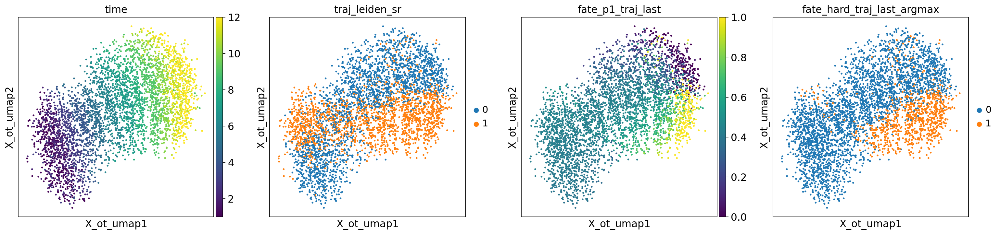

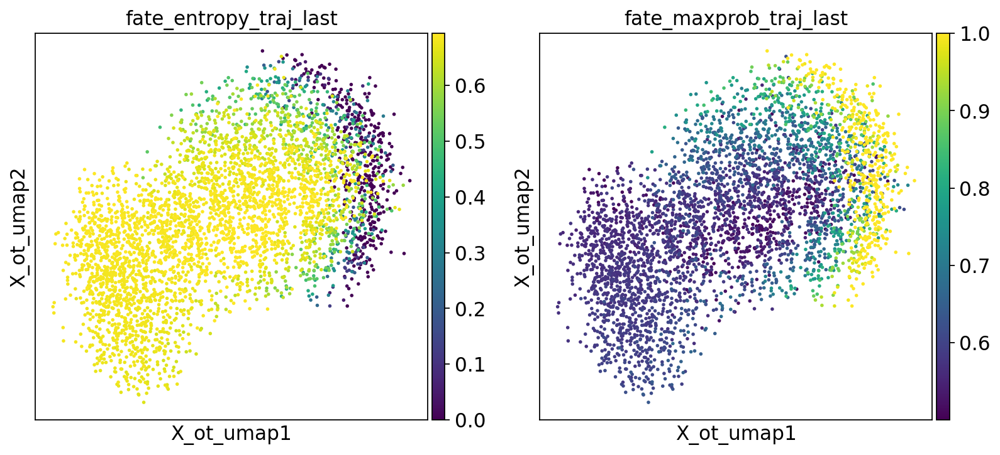

In [14]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import scanpy as sc
import matplotlib.pyplot as plt

# ============================================================
# Terminal fates = traj_leiden_sr clusters at LAST timepoint
# Compute soft fate probabilities for ALL cells using forward kernel T_pruned
#   - K=2 fates: cluster "0" vs "1" (from adata.obs['traj_leiden_sr'])
#   - Terminal condition at last time bin:
#       F[last_cells, fate] = 1 if in that traj cluster, else 0
#   - Backward DP over time bins (robust to skips):
#       F[t_cells] = rownorm( T[t_cells, future_cells] ) @ F[future_cells]
#   - Stores:
#       adata.obsm['fate_probs_traj_last'] : (n x 2)
#       adata.obs['fate_p0_traj_last'], adata.obs['fate_p1_traj_last']
#       adata.obs['fate_hard_traj_last_argmax']
#   - Visualizes on UMAP
# ============================================================

time_key = "time"
traj_key = "traj_leiden_sr"
basis = "X_ot_umap" if "X_ot_umap" in adata.obsm else ("X_umap" if "X_umap" in adata.obsm else ("X_ot_snn_umap" if "X_ot_snn_umap" in adata.obsm else "X_pca"))

assert "T_pruned" in globals(), "Need T_pruned in scope."
assert sp.issparse(T_pruned), "T_pruned must be sparse."
assert T_pruned.shape == (adata.n_obs, adata.n_obs), "T_pruned must be n_cells x n_cells."
assert time_key in adata.obs, f"Need adata.obs['{time_key}']"
assert traj_key in adata.obs, f"Need adata.obs['{traj_key}'] with categories '0' and '1'"

T = T_pruned.tocsr().astype(np.float64)

# ---- time bins (ordered) ----
t = adata.obs[time_key]
if hasattr(t, "cat"):
    time_levels = list(t.cat.categories)
else:
    time_levels = sorted(pd.unique(t))
tt = t.to_numpy().astype(object)

idx_by_time_all = [np.where(tt == lvl)[0] for lvl in time_levels]
idx_by_time = [ii for ii in idx_by_time_all if ii.size > 0]
time_levels_nonempty = [lvl for lvl, ii in zip(time_levels, idx_by_time_all) if ii.size > 0]
assert len(idx_by_time) >= 2, "Need at least 2 timepoints."

idx_last = idx_by_time[-1]
lvl_last = time_levels_nonempty[-1]
print(f"Terminal timepoint: {lvl_last} | n_last={idx_last.size}")

# ---- terminal labels at last timepoint ----
labs_last = adata.obs[traj_key].astype(str).to_numpy()[idx_last]
# expect "0"/"1"
valid = np.isin(labs_last, ["0", "1"])
if not np.all(valid):
    bad = np.sum(~valid)
    raise ValueError(f"Found {bad} last-timepoint cells with traj labels not in {{'0','1'}}.")

labs_last_int = labs_last.astype(int)
K = 2

# ---- initialize fate prob matrix ----
n = adata.n_obs
F = np.zeros((n, K), dtype=np.float64)
F[idx_last, 0] = (labs_last_int == 0).astype(np.float64)
F[idx_last, 1] = (labs_last_int == 1).astype(np.float64)

# ---- backward DP (use ALL future bins to allow skips) ----
eps = 1e-12
for ti in range(len(idx_by_time) - 2, -1, -1):
    ii = idx_by_time[ti]
    future_idx = np.concatenate(idx_by_time[ti + 1:])

    T_sub = T[ii][:, future_idx]  # rows=ii, cols=future
    denom = np.asarray(T_sub.sum(axis=1)).ravel()

    Fi = (T_sub @ F[future_idx])  # dense (len(ii) x 2)
    ok = denom > 0
    Fi[ok] /= (denom[ok, None] + eps)
    Fi[~ok] = 0.0

    F[ii, :] = Fi

# safety normalize
rs = F.sum(axis=1)
ok = rs > 0
F[ok, :] /= (rs[ok, None] + eps)

# ---- store ----
fate_key = "fate_probs_traj_last"
adata.obsm[fate_key] = F.astype(np.float32)
adata.obs["fate_p0_traj_last"] = F[:, 0].astype(np.float32)
adata.obs["fate_p1_traj_last"] = F[:, 1].astype(np.float32)

adata.obs["fate_hard_traj_last_argmax"] = pd.Categorical(
    np.argmax(F, axis=1).astype(str),
    categories=["0", "1"]
)

print(f"Stored adata.obsm['{fate_key}'] and obs columns fate_p0_traj_last / fate_p1_traj_last.")

# ---- visualize ----
sc.pl.embedding(
    adata,
    basis=basis,
    color=[time_key, traj_key, "fate_p1_traj_last", "fate_hard_traj_last_argmax"],
    ncols=4,
    size=25,
    cmap="viridis"
)

import numpy as np
import scanpy as sc

# ============================================================
# Fate probability entropy per cell
#   - uses adata.obsm['fate_probs_traj_last'] (n x 2 or n x K)
#   - stores:
#       adata.obs['fate_entropy_traj_last']  (natural log)
#       adata.obs['fate_maxprob_traj_last']  (optional confidence)
#   - visualizes on UMAP
# ============================================================

basis = "X_ot_umap" if "X_ot_umap" in adata.obsm else ("X_umap" if "X_umap" in adata.obsm else "X_pca")
fate_key = "fate_probs_traj_last"

assert fate_key in adata.obsm, f"Need adata.obsm['{fate_key}'] from the fate-probabilities cell."

F = np.asarray(adata.obsm[fate_key], dtype=np.float64)
eps = 1e-12

# row-normalize (safety)
rs = F.sum(axis=1, keepdims=True)
F = F / (rs + eps)

# entropy H = -sum_k p_k log p_k
H = -(F * np.log(F + eps)).sum(axis=1)

# optional: max prob as a "confidence" score
maxp = F.max(axis=1)

adata.obs["fate_entropy_traj_last"] = H.astype(np.float32)
adata.obs["fate_maxprob_traj_last"] = maxp.astype(np.float32)

sc.pl.embedding(
    adata,
    basis=basis,
    color=["fate_entropy_traj_last", "fate_maxprob_traj_last"],
    ncols=2,
    size=25,
    cmap="viridis"
)

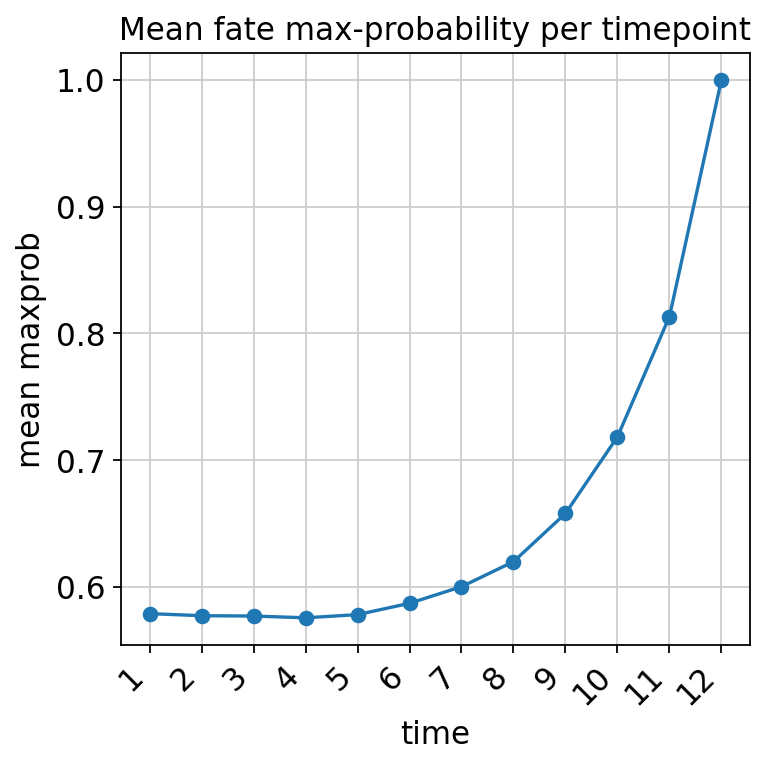

time=1 | n=  363 | mean_maxprob=0.5790
time=2 | n=  348 | mean_maxprob=0.5773
time=3 | n=  307 | mean_maxprob=0.5771
time=4 | n=  299 | mean_maxprob=0.5757
time=5 | n=  269 | mean_maxprob=0.5782
time=6 | n=  340 | mean_maxprob=0.5871
time=7 | n=  386 | mean_maxprob=0.6002
time=8 | n=  310 | mean_maxprob=0.6199
time=9 | n=  426 | mean_maxprob=0.6580
time=10 | n=  306 | mean_maxprob=0.7184
time=11 | n=  310 | mean_maxprob=0.8132
time=12 | n=  370 | mean_maxprob=1.0000


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Mean fate max-probability per timepoint
#   - uses adata.obs['fate_maxprob_traj_last']
# ============================================================

time_key = "time"
col = "fate_maxprob_traj_last"

assert time_key in adata.obs, f"Need adata.obs['{time_key}']"
assert col in adata.obs, f"Need adata.obs['{col}'] (run the entropy cell first)."

t = adata.obs[time_key]
x = adata.obs[col].to_numpy(dtype=float)

# ordered time levels
if hasattr(t, "cat"):
    time_levels = list(t.cat.categories)
else:
    time_levels = sorted(pd.unique(t))

tt = t.to_numpy().astype(object)

means = []
ns = []
levels = []
for lvl in time_levels:
    ii = np.where(tt == lvl)[0]
    if ii.size == 0:
        continue
    means.append(float(np.mean(x[ii])))
    ns.append(int(ii.size))
    levels.append(lvl)

plt.figure()
plt.plot(np.arange(len(means)), means, marker="o")
plt.xticks(np.arange(len(means)), [str(l) for l in levels], rotation=45, ha="right")
plt.xlabel("time")
plt.ylabel("mean maxprob")
plt.title("Mean fate max-probability per timepoint")
plt.tight_layout()
plt.show()

# Optional: print counts
for lvl, m, n in zip(levels, means, ns):
    print(f"time={lvl} | n={n:5d} | mean_maxprob={m:.4f}")

In [16]:
tmp = adata.obsp["W_terminal_cosine_topk"].copy()

/new-stg/home/alex/miniconda3/envs/wot2/lib/python3.13/site-packages/scipy/sparse/_index.py:210: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_arrayXarray(i, j, x)


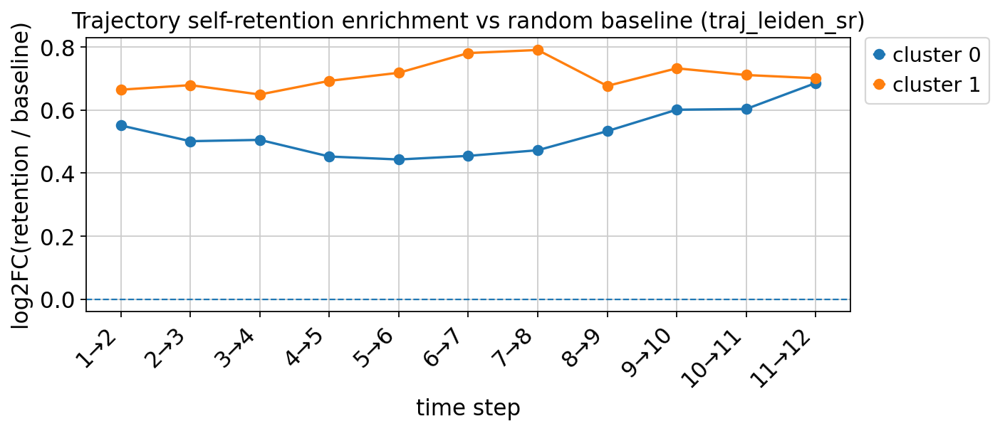

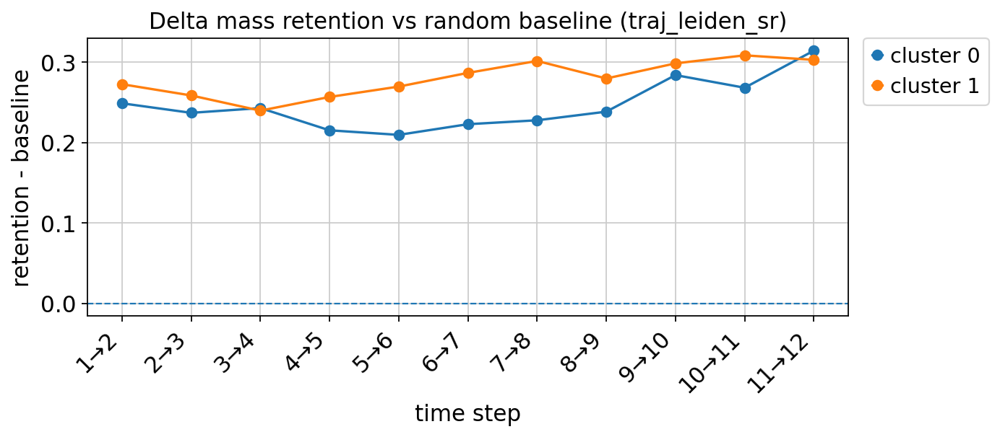

In [17]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

# ============================================================
# logFC (retention vs random baseline) over time for traj_leiden_sr
#   logFC_c(t) = log( retention_c(t) / baseline_c(t) )
#   (set log_base = 2 for log2FC; default = natural log)
#
#   retention_c(t): fraction of mass from cluster c @ time t that lands in cluster c @ time t+1
#   baseline_c(t): expected fraction if destinations were random given cluster size at t+1
#                  = frac of cells in cluster c at time t+1
#
#   Plots logFC over time for clusters 0 and 1.
# ============================================================

time_key = "time"
traj_key = "traj_leiden_sr"
log_base = 2.0          # set to np.e for natural log, 2 for log2FC
eps = 1e-12             # for numerical stability
T = T_pruned.tocsr().astype(np.float64)

assert time_key in adata.obs, f"Need adata.obs['{time_key}']"
assert traj_key in adata.obs, f"Need adata.obs['{traj_key}']"
assert sp.issparse(T) and T.shape == (adata.n_obs, adata.n_obs)

# --- enforce row-stochastic on full T (safe) ---
rs = np.asarray(T.sum(axis=1)).ravel()
zero = rs == 0
if np.any(zero):
    T = T.copy().tocsr()
    T[zero, zero] = 1.0
    rs = np.asarray(T.sum(axis=1)).ravel()
T = sp.diags(1.0 / (rs + 1e-15)) @ T

# --- time bins ---
t = adata.obs[time_key]
if hasattr(t, "cat"):
    time_levels = list(t.cat.categories)
else:
    time_levels = sorted(pd.unique(t))
tt = t.to_numpy().astype(object)

idx_by_time_all = [np.where(tt == lvl)[0] for lvl in time_levels]
idx_by_time = [ii for ii in idx_by_time_all if ii.size > 0]
time_levels_nonempty = [lvl for lvl, ii in zip(time_levels, idx_by_time_all) if ii.size > 0]
assert len(idx_by_time) >= 2, "Need at least 2 timepoints"

lab = adata.obs[traj_key].astype(str).to_numpy()
clusters = ["0", "1"]

n_steps = len(idx_by_time) - 1
ret = {c: np.full(n_steps, np.nan, dtype=float) for c in clusters}
base = {c: np.full(n_steps, np.nan, dtype=float) for c in clusters}

for ti in range(n_steps):
    idx_src = idx_by_time[ti]
    idx_dst = idx_by_time[ti + 1]

    A = T[idx_src, :][:, idx_dst].tocsr()  # (n_src x n_dst)
    denom = np.asarray(A.sum(axis=1)).ravel()

    dst_lab = lab[idx_dst]
    dst_total = idx_dst.size

    for c in clusters:
        src_mask = (lab[idx_src] == c)
        if not np.any(src_mask) or dst_total == 0:
            continue

        src_rows = np.where(src_mask)[0]
        A_c = A[src_rows, :]

        denom_c = denom[src_rows]
        total_out = float(denom_c.sum())
        if total_out <= 0:
            continue

        # baseline = fraction of DESTINATION cells that are in cluster c
        base_c = float(np.mean(dst_lab == c))
        base[c][ti] = base_c

        # retention mass into same-labeled destination cells
        dst_mask_c = (dst_lab == c)
        if np.any(dst_mask_c):
            same_mass = float(A_c[:, np.where(dst_mask_c)[0]].sum())
        else:
            same_mass = 0.0

        ret[c][ti] = same_mass / total_out

# --- compute logFC with clipping ---
def _log_fc(a, b, eps=1e-12, log_base=2.0):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    ratio = (np.clip(a, eps, None) / np.clip(b, eps, None))
    if log_base == np.e:
        return np.log(ratio)
    else:
        return np.log(ratio) / np.log(log_base)

logFC = {c: _log_fc(ret[c], base[c], eps=eps, log_base=log_base) for c in clusters}

# --- plot ---
x = np.arange(n_steps)
xlab = [f"{time_levels_nonempty[i]}→{time_levels_nonempty[i+1]}" for i in range(n_steps)]
ylabel = "log2FC(retention / baseline)" if log_base == 2.0 else "logFC(retention / baseline)"

plt.figure(figsize=(9, 4))
for c in clusters:
    plt.plot(x, logFC[c], marker="o", linewidth=1.5, label=f"cluster {c}")
plt.axhline(0.0, linestyle="--", linewidth=1.0)  # ratio=1 baseline
plt.xticks(x, [str(s) for s in xlab], rotation=45, ha="right")
plt.xlabel("time step")
plt.ylabel(ylabel)
plt.title(f"Trajectory self-retention enrichment vs random baseline ({traj_key})")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
plt.tight_layout()
plt.show()

# Optional: store in adata.uns for later reuse
adata.uns["traj_retention"] = {"ret": ret, "base": base, "logFC": logFC, "time_steps": [str(s) for s in xlab]}

# --- delta ---
delta = {c: (ret[c] - base[c]) for c in clusters}

# --- plot ---
x = np.arange(n_steps)
xlab = [f"{time_levels_nonempty[i]}→{time_levels_nonempty[i+1]}" for i in range(n_steps)]

plt.figure(figsize=(9, 4))
for c in clusters:
    plt.plot(x, delta[c], marker="o", linewidth=1.5, label=f"cluster {c}")
plt.axhline(0.0, linestyle="--", linewidth=1.0)  # retention == baseline
plt.xticks(x, [str(s) for s in xlab], rotation=45, ha="right")
plt.xlabel("time step")
plt.ylabel("retention - baseline")
plt.title(f"Delta mass retention vs random baseline ({traj_key})")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
plt.tight_layout()
plt.show()

# optional: stash
adata.uns["traj_retention_delta"] = {"delta": delta, "ret": ret, "base": base, "time_steps": [str(s) for s in xlab]}

/new-stg/home/alex/miniconda3/envs/wot2/lib/python3.13/site-packages/scipy/sparse/_index.py:210: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_arrayXarray(i, j, x)


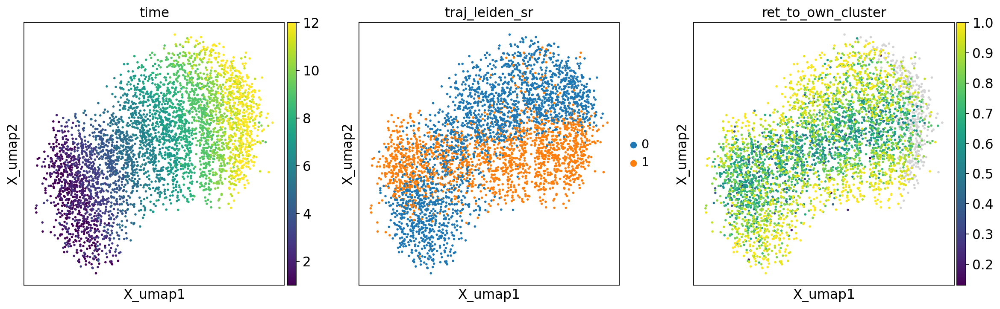


Per-time retention-to-own summary:
      count      mean    median       std
time                                     
1       363  0.764223  0.779214  0.164161
2       348  0.751730  0.761630  0.167011
3       307  0.752404  0.770885  0.179019
4       299  0.745741  0.771721  0.185276
5       269  0.748227  0.755810  0.172643
6       340  0.765994  0.793730  0.174304
7       386  0.774615  0.794974  0.175481
8       310  0.761037  0.768385  0.170797
9       426  0.793766  0.830334  0.167264
10      306  0.787778  0.821351  0.162747
11      310  0.809100  0.827234  0.146604
12        0       NaN       NaN       NaN


In [18]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import scanpy as sc

# ============================================================
# Per-cell "mass retention to own cluster" on UMAP
#   For each cell i at time t (except last timepoint):
#     let c_i = traj cluster label (0/1)
#     look at forward mass from i -> cells at time t+1 via T_pruned block
#     retention_i = mass landing in cluster c_i at t+1 / total mass from i to t+1
#
#   Stores:
#     adata.obs['ret_to_own_cluster']  (float in [0,1], NaN for last timepoint or no outgoing mass)
#     adata.obs['ret_to_other_cluster'] (=1-ret, when defined)
# ============================================================

time_key = "time"
traj_key = "traj_leiden_sr"  # must be '0'/'1' for all cells
basis = "X_umap" if "X_umap" in adata.obsm else ("X_ot_umap" if "X_ot_umap" in adata.obsm else "X_pca")

assert time_key in adata.obs, f"Need adata.obs['{time_key}']"
assert traj_key in adata.obs, f"Need adata.obs['{traj_key}']"
assert "T_pruned" in globals(), "Need T_pruned in scope."
assert sp.issparse(T_pruned), "T_pruned must be sparse."

T = T_pruned.tocsr().astype(np.float64)

# row-stochastic (safe)
rs = np.asarray(T.sum(axis=1)).ravel()
zero = rs == 0
if np.any(zero):
    T = T.copy().tocsr()
    T[zero, zero] = 1.0
    rs = np.asarray(T.sum(axis=1)).ravel()
T = sp.diags(1.0 / (rs + 1e-15)) @ T

# time bins
t = adata.obs[time_key]
tt = t.to_numpy().astype(object)
time_levels = list(t.cat.categories) if hasattr(t, "cat") else sorted(pd.unique(tt))
idx_by_time_all = [np.where(tt == lvl)[0] for lvl in time_levels]
idx_by_time = [ii for ii in idx_by_time_all if ii.size > 0]
time_levels_nonempty = [lvl for lvl, ii in zip(time_levels, idx_by_time_all) if ii.size > 0]
assert len(idx_by_time) >= 2

# labels 0/1
lab = adata.obs[traj_key].astype(str).to_numpy()
if not np.all(np.isin(lab, ["0", "1"])):
    raise ValueError(f"{traj_key} must contain only '0'/'1'.")
lab01 = lab.astype(int)

ret_own = np.full(adata.n_obs, np.nan, dtype=np.float32)

for ti in range(len(idx_by_time) - 1):
    idx_src = idx_by_time[ti]
    idx_dst = idx_by_time[ti + 1]

    A = T[idx_src, :][:, idx_dst].tocsr()  # (n_src x n_dst)
    denom = np.asarray(A.sum(axis=1)).ravel()  # should be ~1, but keep general

    dst_lab01 = lab01[idx_dst]
    dst_mask0 = (dst_lab01 == 0)
    dst_mask1 = ~dst_mask0

    # mass to cluster0 / cluster1 for each source cell
    m0 = np.asarray(A[:, dst_mask0].sum(axis=1)).ravel()
    m1 = np.asarray(A[:, dst_mask1].sum(axis=1)).ravel()

    # pick "own" mass based on src label
    own = np.where(lab01[idx_src] == 0, m0, m1)

    # retention fraction (guard against denom==0)
    ok = denom > 0
    r = np.full(idx_src.size, np.nan, dtype=np.float32)
    r[ok] = (own[ok] / denom[ok]).astype(np.float32)

    ret_own[idx_src] = r

adata.obs["ret_to_own_cluster"] = ret_own
# (optional convenience)
adata.obs["ret_to_other_cluster"] = (1.0 - ret_own)

# visualize
sc.pl.embedding(
    adata,
    basis=basis,
    color=[time_key, traj_key, "ret_to_own_cluster"],
    ncols=3,
    size=25,
    cmap="viridis"
)

# Optional: quick per-time summary
df = pd.DataFrame({"time": tt, "ret": ret_own})
summ = df.groupby("time")["ret"].agg(["count", "mean", "median", "std"])
print("\nPer-time retention-to-own summary:")
print(summ.to_string())

/new-stg/home/alex/miniconda3/envs/wot2/lib/python3.13/site-packages/scipy/sparse/_index.py:210: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_arrayXarray(i, j, x)


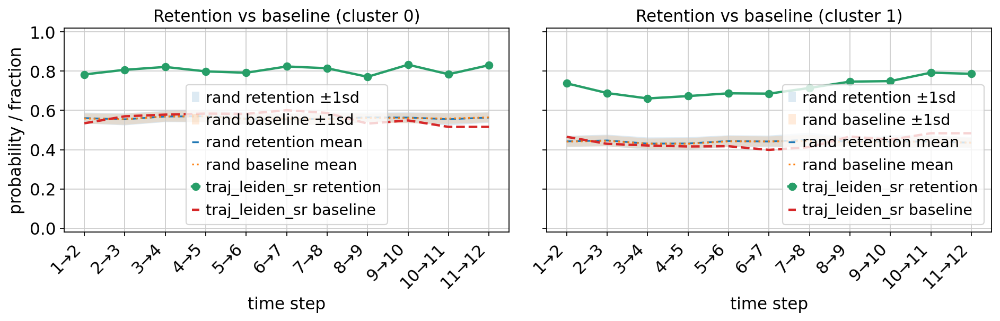

In [19]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

# ============================================================
# Follow-up: retention vs random baseline (cluster-level curves)
#   Plots, for each cluster c:
#     - traj retention_c(t) (solid)
#     - traj baseline_c(t)  (dashed)
#     - random partitions retention mean±sd band
#     - random partitions baseline mean±sd band
# ============================================================

time_key = "time"
traj_key = "traj_leiden_sr"
n_reps = 30
eps = 1e-12

assert time_key in adata.obs
assert traj_key in adata.obs
assert "T_pruned" in globals() and sp.issparse(T_pruned)

# --- row-stochastic ---
T = T_pruned.tocsr().astype(np.float64)
rs = np.asarray(T.sum(axis=1)).ravel()
z = rs == 0
if np.any(z):
    T = T.copy().tocsr()
    T[z, z] = 1.0
    rs = np.asarray(T.sum(axis=1)).ravel()
T = sp.diags(1.0 / (rs + 1e-15)) @ T

# --- time bins ---
t = adata.obs[time_key]
tt = t.to_numpy().astype(object)
time_levels = list(t.cat.categories) if hasattr(t, "cat") else sorted(pd.unique(tt))
idx_by_time_all = [np.where(tt == lvl)[0] for lvl in time_levels]
idx_by_time = [ii for ii in idx_by_time_all if ii.size > 0]
time_levels_nonempty = [lvl for lvl, ii in zip(time_levels, idx_by_time_all) if ii.size > 0]
n_steps = len(idx_by_time) - 1
assert n_steps >= 1
x = np.arange(n_steps)
xlab = [f"{time_levels_nonempty[i]}→{time_levels_nonempty[i+1]}" for i in range(n_steps)]

def retention_vs_baseline_for_labels(labels01):
    labels01 = np.asarray(labels01, dtype=int)
    out = {
        "ret":  np.full((n_steps, 2), np.nan, dtype=float),
        "base": np.full((n_steps, 2), np.nan, dtype=float),
    }
    for ti in range(n_steps):
        idx_src = idx_by_time[ti]
        idx_dst = idx_by_time[ti+1]
        A = T[idx_src, :][:, idx_dst].tocsr()
        denom = np.asarray(A.sum(axis=1)).ravel()
        dst_lab = labels01[idx_dst]

        for c in (0, 1):
            src_mask = (labels01[idx_src] == c)
            if not np.any(src_mask):
                continue
            src_rows = np.where(src_mask)[0]
            total_out = float(denom[src_rows].sum())
            if total_out <= 0:
                continue

            base_c = float(np.mean(dst_lab == c))
            out["base"][ti, c] = base_c

            dst_mask_c = (dst_lab == c)
            same_mass = float(A[src_rows, :][:, np.where(dst_mask_c)[0]].sum()) if np.any(dst_mask_c) else 0.0
            out["ret"][ti, c] = same_mass / total_out
    return out

def stack_metric(stats_list, key):
    return np.stack([s[key] for s in stats_list], axis=0)  # (R, n_steps, 2)

# traj labels
traj_lab = adata.obs[traj_key].astype(str).to_numpy()
if not np.all(np.isin(traj_lab, ["0", "1"])):
    raise ValueError(f"{traj_key} must contain only '0'/'1'.")
traj_lab01 = traj_lab.astype(int)
traj_stats = retention_vs_baseline_for_labels(traj_lab01)

# random partitions preserving global p1
p1 = float(np.mean(traj_lab01 == 1))
m = int(round(p1 * adata.n_obs))
rng = np.random.default_rng(0)

rand_stats_all = []
for _ in range(n_reps):
    lab = np.zeros(adata.n_obs, dtype=int)
    idx1 = rng.choice(adata.n_obs, size=m, replace=False)
    lab[idx1] = 1
    rand_stats_all.append(retention_vs_baseline_for_labels(lab))

rand_ret  = stack_metric(rand_stats_all, "ret")
rand_base = stack_metric(rand_stats_all, "base")

rand_ret_mean  = np.nanmean(rand_ret, axis=0);  rand_ret_std  = np.nanstd(rand_ret, axis=0)
rand_base_mean = np.nanmean(rand_base, axis=0); rand_base_std = np.nanstd(rand_base, axis=0)

# plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for c, ax in enumerate(axes):
    # random bands
    ax.fill_between(x, rand_ret_mean[:, c]  - rand_ret_std[:, c],  rand_ret_mean[:, c]  + rand_ret_std[:, c],
                    alpha=0.15, label="rand retention ±1sd")
    ax.fill_between(x, rand_base_mean[:, c] - rand_base_std[:, c], rand_base_mean[:, c] + rand_base_std[:, c],
                    alpha=0.15, label="rand baseline ±1sd")

    ax.plot(x, rand_ret_mean[:, c],  linestyle="--", linewidth=1.5, label="rand retention mean")
    ax.plot(x, rand_base_mean[:, c], linestyle=":",  linewidth=1.5, label="rand baseline mean")

    # traj curves
    ax.plot(x, traj_stats["ret"][:, c],  marker="o", linewidth=2.0, label=f"{traj_key} retention")
    ax.plot(x, traj_stats["base"][:, c], linestyle="--", linewidth=2.0, label=f"{traj_key} baseline")

    ax.set_title(f"Retention vs baseline (cluster {c})")
    ax.set_ylim(-0.02, 1.02)
    ax.set_xticks(x)
    ax.set_xticklabels([str(s) for s in xlab], rotation=45, ha="right")
    ax.set_xlabel("time step")
    if c == 0:
        ax.set_ylabel("probability / fraction")
    ax.legend(loc="best")

plt.tight_layout()
plt.show()

In [20]:
import numpy as np
import pandas as pd
import scipy.sparse as sp

# ============================================================
# Mass retention (%) per cluster + baseline expected from cluster size
#
# For each step t -> t+1 and cluster c:
#   retention_c(t) = mass from cluster c@t landing in cluster c@t+1 / total mass from cluster c@t into t+1
#   baseline_c(t)  = fraction of DESTINATION cells (t+1) in cluster c   (size-only expectation)
#
# Overall (pooled across steps, mass-weighted):
#   overall_ret_c = sum_t same_mass_c(t) / sum_t total_out_mass_c(t)
#   overall_base_c = sum_t [ baseline_c(t) * total_out_mass_c(t) ] / sum_t total_out_mass_c(t)
#
# Stores:
#   adata.uns['cluster_ret_base_by_step'] : DataFrame with ret/base for each cluster
#   adata.uns['cluster_ret_base_overall'] : Series with overall ret/base for each cluster
# ============================================================

time_key = "time"
traj_key = "traj_leiden_sr"
eps = 1e-12

assert time_key in adata.obs, f"Need adata.obs['{time_key}']"
assert traj_key in adata.obs, f"Need adata.obs['{traj_key}']"
assert "T_pruned" in globals(), "Need T_pruned in scope."
assert sp.issparse(T_pruned), "T_pruned must be sparse."
assert T_pruned.shape == (adata.n_obs, adata.n_obs)

# --- row-stochastic forward kernel ---
T = T_pruned.tocsr().astype(np.float64)
rs = np.asarray(T.sum(axis=1)).ravel()
z = rs == 0
if np.any(z):
    T = T.copy().tocsr()
    T[z, z] = 1.0
    rs = np.asarray(T.sum(axis=1)).ravel()
T = sp.diags(1.0 / (rs + 1e-15)) @ T

# --- time bins ---
t = adata.obs[time_key]
tt = t.to_numpy().astype(object)
time_levels = list(t.cat.categories) if hasattr(t, "cat") else sorted(pd.unique(tt))
idx_by_time_all = [np.where(tt == lvl)[0] for lvl in time_levels]
idx_by_time = [ii for ii in idx_by_time_all if ii.size > 0]
time_levels_nonempty = [lvl for lvl, ii in zip(time_levels, idx_by_time_all) if ii.size > 0]
assert len(idx_by_time) >= 2, "Need at least 2 timepoints."

# --- labels 0/1 ---
lab = adata.obs[traj_key].astype(str).to_numpy()
if not np.all(np.isin(lab, ["0", "1"])):
    raise ValueError(f"{traj_key} must contain only '0'/'1'.")
lab01 = lab.astype(int)

n_steps = len(idx_by_time) - 1
step_names = [f"{time_levels_nonempty[i]}→{time_levels_nonempty[i+1]}" for i in range(n_steps)]

ret = np.full((n_steps, 2), np.nan, dtype=float)
base = np.full((n_steps, 2), np.nan, dtype=float)
total_out = np.full((n_steps, 2), np.nan, dtype=float)
same_mass = np.full((n_steps, 2), np.nan, dtype=float)

for ti in range(n_steps):
    idx_src = idx_by_time[ti]
    idx_dst = idx_by_time[ti + 1]

    A = T[idx_src, :][:, idx_dst].tocsr()
    denom = np.asarray(A.sum(axis=1)).ravel()  # per-cell outgoing to t+1

    dst_lab = lab01[idx_dst]
    frac0 = float(np.mean(dst_lab == 0))
    frac1 = 1.0 - frac0
    dst_mask0 = (dst_lab == 0)
    dst_mask1 = ~dst_mask0

    for c in (0, 1):
        src_mask = (lab01[idx_src] == c)
        if not np.any(src_mask):
            continue

        src_rows = np.where(src_mask)[0]
        tot = float(denom[src_rows].sum())
        total_out[ti, c] = tot
        if tot <= eps:
            continue

        # baseline: destination fraction in cluster c (size-only expectation)
        base_c = frac0 if c == 0 else frac1
        base[ti, c] = base_c

        # same-cluster mass
        dst_mask_c = dst_mask0 if c == 0 else dst_mask1
        sm = float(A[src_rows, :][:, np.where(dst_mask_c)[0]].sum()) if np.any(dst_mask_c) else 0.0
        same_mass[ti, c] = sm

        ret[ti, c] = sm / tot

# per-step table (percent)
df = pd.DataFrame(
    {
        "ret_cluster0_%": 100 * ret[:, 0],
        "base_cluster0_%": 100 * base[:, 0],
        "ret_cluster1_%": 100 * ret[:, 1],
        "base_cluster1_%": 100 * base[:, 1],
    },
    index=step_names,
)
adata.uns["cluster_ret_base_by_step"] = df

# overall pooled (mass-weighted over steps)
overall_ret = np.zeros(2, dtype=float)
overall_base = np.zeros(2, dtype=float)

for c in (0, 1):
    tot = np.nansum(total_out[:, c])
    if tot <= eps:
        overall_ret[c] = np.nan
        overall_base[c] = np.nan
        continue

    overall_ret[c] = np.nansum(same_mass[:, c]) / tot
    # expected same-cluster mass under baseline each step is base(t,c) * total_out(t,c)
    overall_base[c] = np.nansum(base[:, c] * total_out[:, c]) / tot

overall = pd.Series(
    {
        "overall_ret_cluster0_%": 100 * overall_ret[0],
        "overall_base_cluster0_%": 100 * overall_base[0],
        "overall_ret_cluster1_%": 100 * overall_ret[1],
        "overall_base_cluster1_%": 100 * overall_base[1],
    }
)
adata.uns["cluster_ret_base_overall"] = overall

print("Per-step retention vs baseline (%):")
print(df.round(2).to_string())

print("\nOverall (pooled, mass-weighted) retention vs baseline (%):")
print(overall.round(2).to_string())

Per-step retention vs baseline (%):
       ret_cluster0_%  base_cluster0_%  ret_cluster1_%  base_cluster1_%
1→2             78.32            53.45           73.79            46.55
2→3             80.69            57.00           68.84            43.00
3→4             82.14            57.86           66.10            42.14
4→5             79.88            58.36           67.29            41.64
5→6             79.18            58.24           68.71            41.76
6→7             82.38            60.10           68.55            39.90
7→8             81.47            58.71           71.42            41.29
8→9             77.12            53.29           74.67            46.71
9→10            83.28            54.90           74.93            45.10
10→11           78.42            51.61           79.22            48.39
11→12           83.03            51.62           78.65            48.38

Overall (pooled, mass-weighted) retention vs baseline (%):
overall_ret_cluster0_%     80.60
overall

/new-stg/home/alex/miniconda3/envs/wot2/lib/python3.13/site-packages/scipy/sparse/_index.py:210: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_arrayXarray(i, j, x)


In [21]:
adata_full_out = adata_full[adata.obs_names, :].copy()
adata_full_out.obs = adata.obs.copy()
adata_full_out.obsm = adata.obsm.copy()
adata_full_out.obsp = adata.obsp.copy()
adata_full_out.uns = adata.uns.copy()

for _adata_to_write in (adata_full_out, adata):
    for _key, _value in list(_adata_to_write.uns.items()):
        if isinstance(_value, pd.Series):
            _adata_to_write.uns[_key] = _value.to_frame("value")

adata_full_out.write_h5ad('../output/adata_full.h5ad')
adata.write_h5ad('../output/adata_hvg.h5ad')
